**Analisis Sentimen Pengguna terhadap Layanan OVO di Indonesia Berdasarkan Ulasan Google Play**

**Dataset**

In [ ]:
df.to_csv('dataset_ovo.csv', index=False)

**Install Library**

In [ ]:
pip install google-play-scraper pandas numpy scikit-learn sastrawi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 8.6 MB/s eta 0:00:00


**Scraping Data Google Play**

In [ ]:
from google_play_scraper import reviews, Sort
import pandas as pd

app_id = 'ovo.id'

result, _ = reviews(
    app_id,
    lang='id',
    country='id',
    sort=Sort.NEWEST,
    count=3000
)
2
df = pd.DataFrame(result)

# Ambil kolom penting
df = df[['content', 'score']]
df.columns = ['ulasan', 'rating']

print(df.head())

                                              ulasan  rating
0  bagus pake ovo cuma banyak gangguan truz yg bi...       5
1  apk parah amat belanja peke payletter ovo ,56 ...       1
2                                             kurang       1
3  penguna lama saya tolong ditingkatkan uodateny...       5
4                                            Terbaik       5


**Preprocessing Text**

In [ ]:
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# stemmer & stopword
stemmer = StemmerFactory().create_stemmer()
stopword = StopWordRemoverFactory().create_stop_word_remover()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)  # hapus link
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # hapus angka & simbol
    text = stopword.remove(text)
    text = stemmer.stem(text)
    return text

df['clean'] = df['ulasan'].apply(clean_text)

print(df.head())

                                              ulasan  rating  \
0  bagus pake ovo cuma banyak gangguan truz yg bi...       5   
1  apk parah amat belanja peke payletter ovo ,56 ...       1   
2                                             kurang       1   
3  penguna lama saya tolong ditingkatkan uodateny...       5   
4                                            Terbaik       5   

                                               clean  
0  bagus pake ovo cuma banyak ganggu truz yg biki...  
1  apk parah belanja peke payletter ovo rb biaya ...  
2                                             kurang  
3  penguna lama tolong tingkat uodatenya jangan s...  
4                                               baik  


### 1. Filtering Ulasan Pendek atau Tidak Relevan

Langkah ini bertujuan untuk menghapus ulasan yang terlalu singkat atau tidak memberikan informasi yang cukup setelah proses pembersihan awal. Kita akan menghapus ulasan yang memiliki kurang dari 3 kata setelah dibersihkan.

In [ ]:
# Hitung jumlah kata dalam kolom 'clean'
df['word_count'] = df['clean'].apply(lambda x: len(x.split()))

# Filter ulasan dengan jumlah kata kurang dari 3
df_filtered = df[df['word_count'] >= 3].copy()

print(f"Jumlah ulasan sebelum filtering: {len(df)}")
print(f"Jumlah ulasan setelah filtering (min 3 kata): {len(df_filtered)}")

# Drop kolom 'word_count' sementara jika tidak diperlukan lagi
df_filtered = df_filtered.drop(columns=['word_count'])

# Update df ke df_filtered
df = df_filtered

display(df.head())

Jumlah ulasan sebelum filtering: 3000
Jumlah ulasan setelah filtering (min 3 kata): 2409


,ulasan,rating,clean,sentimen
0,bagus pake ovo cuma banyak gangguan truz yg bi...,5,bagus pake ovo cuma banyak ganggu truz yg biki...,positif
1,"apk parah amat belanja peke payletter ovo ,56 ...",1,apk parah belanja peke payletter ovo rb biaya ...,negatif
3,penguna lama saya tolong ditingkatkan uodateny...,5,penguna lama tolong tingkat uodatenya jangan s...,positif
5,"untuk pengguna ovo, sebaiknya jangan lagi meng...",1,guna ovo baik jangan guna ovo dalam dapat bany...,negatif
7,xsis terus bersama OVO,5,xsis terus sama ovo,positif


### 2. Advanced Normalization: Slang-to-Formal

Tahap ini akan mengubah kata-kata gaul menjadi bentuk formalnya. Untuk implementasi yang lebih komprehensif, Anda memerlukan kamus kata gaul (slang dictionary) yang lengkap. Di sini, saya akan menggunakan contoh kamus sederhana. Anda bisa memperluas kamus ini sesuai kebutuhan.

In [ ]:
# Contoh Kamus Slang-to-Formal (Perlu diperluas)
slang_dict = {
    'bgt': 'banget',
    'kyk': 'seperti',
    'jg': 'juga',
    'udh': 'sudah',
    'gk': 'tidak',
    'ga': 'tidak',
    'tdk': 'tidak',
    'jd': 'jadi',
    'dr': 'dari',
    'sih': '', # Hapus kata seru yang tidak perlu
    'aja': 'saja',
    'bgus': 'bagus',
    'pke': 'pakai',
    'peke': 'pakai',
    'pdh': 'padahal',
    'bkn': 'bukan',
    'klo': 'kalau',
    'trs': 'terus',
    'ato': 'atau',
    'mksh': 'terima kasih'
}

def normalize_slang(text):
    words = text.split()
    normalized_words = [slang_dict.get(word, word) for word in words]
    return ' '.join(normalized_words)

# Terapkan normalisasi slang ke kolom 'clean'
df['clean_normalized'] = df['clean'].apply(normalize_slang)

display(df.head())

,ulasan,rating,clean,sentimen,clean_normalized
0,bagus pake ovo cuma banyak gangguan truz yg bi...,5,bagus pake ovo cuma banyak ganggu truz yg biki...,positif,bagus pake ovo cuma banyak ganggu truz yg biki...
1,"apk parah amat belanja peke payletter ovo ,56 ...",1,apk parah belanja peke payletter ovo rb biaya ...,negatif,apk parah belanja pakai payletter ovo rb biaya...
3,penguna lama saya tolong ditingkatkan uodateny...,5,penguna lama tolong tingkat uodatenya jangan s...,positif,penguna lama tolong tingkat uodatenya jangan s...
5,"untuk pengguna ovo, sebaiknya jangan lagi meng...",1,guna ovo baik jangan guna ovo dalam dapat bany...,negatif,guna ovo baik jangan guna ovo dalam dapat bany...
7,xsis terus bersama OVO,5,xsis terus sama ovo,positif,xsis terus sama ovo


### 3. Validasi Manual Hasil Preprocessing

Untuk memastikan bahwa proses pembersihan dan normalisasi tidak mengubah makna asli ulasan dan berjalan dengan baik, kita akan menampilkan beberapa sampel data secara acak untuk inspeksi manual. Ini penting untuk menjaga 'Data Integrity'.

In [ ]:
# Tampilkan 10 sampel acak untuk perbandingan manual
sample_df = df[['ulasan', 'clean', 'clean_normalized', 'sentimen']].sample(10, random_state=42)
display(sample_df)

,ulasan,clean,clean_normalized,sentimen
2498,aplikasi lemot kirim dr ovo ke bank gagal teru...,aplikasi lot kirim dr ovo bank gagal terus dr ...,aplikasi lot kirim dari ovo bank gagal terus d...,negatif
2579,"aplikasi apaan,lemot lembek lama, hari2 ganggu...",aplikasi apaanlemot lembek lama hari ganggu tr...,aplikasi apaanlemot lembek lama hari ganggu tr...,negatif
2078,"transfer ke rekening lain, lelet banget",transfer rekening lelet banget,transfer rekening lelet banget,negatif
2862,apa² an klo ga niat bikin e-wallet mending ga ...,apa an klo ga niat bikin ewallet mending ga us...,apa an kalau tidak niat bikin ewallet mending ...,negatif
967,"aplikasi ga jelas, banyak bug, biaya admin mah...",aplikasi ga jelas banyak bug biaya admin mahal...,aplikasi tidak jelas banyak bug biaya admin ma...,negatif
2715,lu paling ribet beneran. dri pada aplikasi sej...,lu paling ribet beneran dri aplikasi jenis lain,lu paling ribet beneran dri aplikasi jenis lain,negatif
2041,untuk semua stop pki ovo jgn daftar lg krn dat...,semua stop pki ovo jgn daftar lg krn data kali...,semua stop pki ovo jgn daftar lg krn data kali...,negatif
1887,kenapa gak bisa login bilang akun atau perangk...,gak login bilang akun perangkat dimodifikasigi...,gak login bilang akun perangkat dimodifikasigi...,negatif
1802,keluarr cepet masuk lagi susah tolong jgan dip...,keluarr cepet masuk susah jgan sulit,keluarr cepet masuk susah jgan sulit,negatif
1608,"mau buat akun , ketahan dibuat nama gimana nih...",mau buat akun tahan buat nama gimana nih kasih...,mau buat akun tahan buat nama gimana nih kasih...,negatif


### Catatan:

Setelah langkah-langkah preprocessing ini, disarankan untuk menjalankan kembali proses ekstraksi fitur (TF-IDF) dan pelatihan model untuk melihat apakah ada peningkatan performa, terutama untuk sentimen 'netral' yang sebelumnya memiliki nilai F1-score rendah.

**Labeling Sentimen**

In [ ]:
def label_sentimen(rating):
    if rating <= 2:
        return 'negatif'
    elif rating == 3:
        return 'netral'
    else:
        return 'positif'

df['sentimen'] = df['rating'].apply(label_sentimen)

**Feature Extraction (TF-IDF)**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df['clean'])
y = df['sentimen']

**Split Data**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

**Training Model (Naive Bayes)**

In [ ]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train, y_train)

MultinomialNB()

**Evaluasi Model**

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

y_pred = model.predict(X_test)

print("Akurasi:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Akurasi: 0.8066666666666666
              precision    recall  f1-score   support

     negatif       0.78      1.00      0.87       405
      netral       0.00      0.00      0.00        22
     positif       0.99      0.46      0.63       173

    accuracy                           0.81       600
   macro avg       0.59      0.49      0.50       600
weighted avg       0.81      0.81      0.77       600



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Final Task

### Subtask:
Present a summary of the sentiment analysis of OVO user reviews from Google Play, including insights from the model's performance.


# Task
Analyze user sentiment towards OVO services in Indonesia based on Google Play reviews. The task involves scraping review data, performing extensive text preprocessing including slang normalization, training a sentiment classification model using Naive Bayes, evaluating its performance, and finally presenting a comprehensive summary of the findings and insights.

## Visualisasi Word Cloud (Sebelum vs Sesudah Preprocessing)

### Subtask:
Membuat visualisasi 'Word Cloud' dari ulasan sebelum dan sesudah proses preprocessing untuk menunjukkan dampak pembersihan dan normalisasi teks secara visual.


**Reasoning**:
Importing necessary libraries and generating the Word Cloud for original reviews as per instructions.



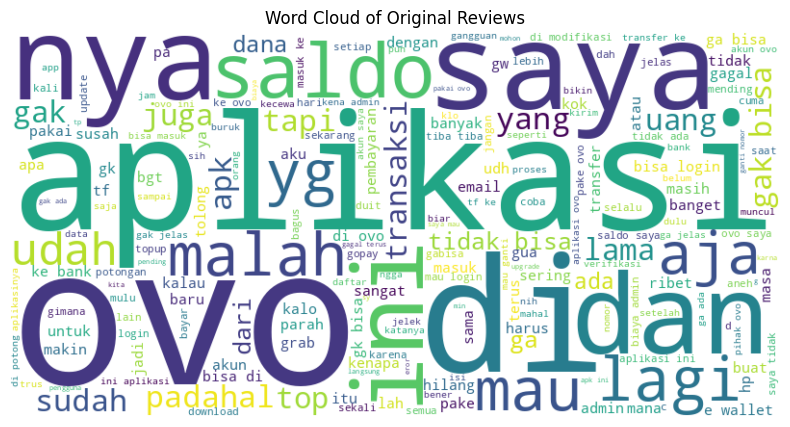

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Concatenate all original reviews
text_original = " ".join(review for review in df['ulasan'])

# Generate Word Cloud for original reviews
wordcloud_original = WordCloud(width=800, height=400, background_color='white').generate(text_original)

# Display the Word Cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_original, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Original Reviews')
plt.show()

**Reasoning**:
Generate the Word Cloud for the preprocessed reviews to show the effect of cleaning and normalization.



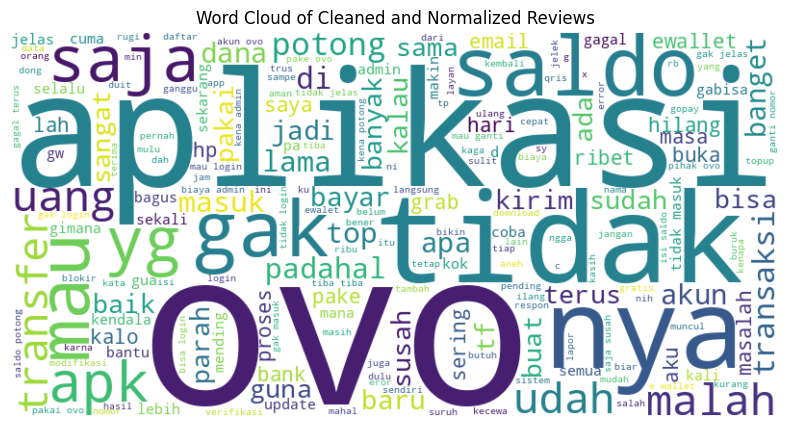

In [ ]:
text_cleaned = " ".join(review for review in df['clean_normalized'])

wordcloud_cleaned = WordCloud(width=800, height=400, background_color='white').generate(text_cleaned)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_cleaned, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Cleaned and Normalized Reviews')
plt.show()


## Data Profiling Ulasan OVO

### Subtask:
Menganalisis karakteristik dataset mentah, termasuk menghitung persentase ulasan duplikat, mengidentifikasi kata-kata gaul/singkatan yang paling sering muncul, dan mengenali jenis noise.


**Reasoning**:
The first instruction for this subtask is to identify and calculate the percentage of duplicate reviews. I will use pandas to find duplicates in the 'ulasan' column and calculate their percentage.



In [ ]:
num_duplicates = df['ulasan'].duplicated().sum()
total_reviews = len(df)
percentage_duplicates = (num_duplicates / total_reviews) * 100

print(f"Jumlah ulasan duplikat: {num_duplicates}")
print(f"Persentase ulasan duplikat: {percentage_duplicates:.2f}%")

Jumlah ulasan duplikat: 2
Persentase ulasan duplikat: 0.08%


**Reasoning**:
I will iterate through the `slang_dict` and count the occurrences of each slang word in the original 'ulasan' column to identify the most frequent ones.



In [ ]:
num_duplicates = df['ulasan'].duplicated().sum()
total_reviews = len(df)
percentage_duplicates = (num_duplicates / total_reviews) * 100

print(f"Jumlah ulasan duplikat: {num_duplicates}")
print(f"Persentase ulasan duplikat: {percentage_duplicates:.2f}%")

# Identify most frequent slang words/abbreviations
slang_counts = {}
for slang, formal in slang_dict.items():
    # Count occurrences of the slang word in the 'ulasan' column
    # Using a regex to match whole words to avoid partial matches (e.g., 'bgt' matching 'banget')
    slang_counts[slang] = df['ulasan'].str.contains(r'\b' + re.escape(slang) + r'\b', case=False, na=False).sum()

# Filter out slangs that didn't appear and sort by count
frequent_slangs = {k: v for k, v in slang_counts.items() if v > 0}
frequent_slangs_sorted = sorted(frequent_slangs.items(), key=lambda item: item[1], reverse=True)

print("\nKata-kata gaul/singkatan yang paling sering muncul:")
for slang, count in frequent_slangs_sorted[:10]: # Display top 10
    print(f"- {slang}: {count} kali")

Jumlah ulasan duplikat: 2
Persentase ulasan duplikat: 0.08%

Kata-kata gaul/singkatan yang paling sering muncul:
- ga: 338 kali
- aja: 292 kali
- gk: 135 kali
- udh: 76 kali
- sih: 64 kali
- bgt: 57 kali
- klo: 46 kali
- tdk: 34 kali
- dr: 27 kali
- jg: 20 kali


**Reasoning**:
I need to identify and count occurrences of different types of noise (URLs, emojis, mentions, numbers) in the original 'ulasan' column to fulfill the subtask's instruction to 'recognize the types of noise'.



In [ ]:
print("\nJenis noise yang ditemukan:")

# Count URLs
url_pattern = r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+'
num_urls = df['ulasan'].str.contains(url_pattern, regex=True).sum()
print(f"- URLs: {num_urls} kali")

# Count Mentions (@user)
mention_pattern = r'@\w+'
num_mentions = df['ulasan'].str.contains(mention_pattern, regex=True).sum()
print(f"- Mentions (@user): {num_mentions} kali")

# Count Numbers (simple digit sequence)
number_pattern = r'\b\d+\b'
num_numbers = df['ulasan'].str.contains(number_pattern, regex=True).sum()
print(f"- Angka: {num_numbers} kali")

# Count Emojis (basic detection, might not catch all unicode emojis)
# This pattern is for common emoji blocks, more comprehensive regex would be very long
emoji_pattern = r'[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF]'
num_emojis = df['ulasan'].str.contains(emoji_pattern, regex=True).sum()
print(f"- Emoji: {num_emojis} kali")



Jenis noise yang ditemukan:
- URLs: 0 kali
- Mentions (@user): 0 kali
- Angka: 355 kali
- Emoji: 104 kali


## Pembersihan Teks Dasar

### Subtask:
Menerapkan langkah-langkah pembersihan dasar pada kolom 'ulasan': 'case folding' (mengubah semua teks menjadi huruf kecil), 'regex cleaning' (menghapus URL, hashtag, angka, dan simbol/karakter yang tidak relevan), 'stopword removal' (menghapus kata-kata umum yang tidak memiliki makna sentimen), dan 'stemming' (mengembalikan kata ke bentuk dasarnya) menggunakan Sastrawi.


## Scraping Data Ulasan OVO

### Subtask:
Scrape reviews and ratings of the OVO application from the Google Play Store, targeting a minimum of 1,000 reviews to form the raw dataset.


## Filtering Ulasan Pendek atau Tidak Relevan

### Subtask:
Menghapus ulasan yang menjadi terlalu pendek atau tidak relevan setelah proses pembersihan dasar. Ulasan dengan jumlah kata kurang dari 3 setelah dibersihkan akan dihapus untuk memastikan kualitas data.


## Normalisasi Kata Gaul (Slang-to-Formal)

### Subtask:
Membangun dan menerapkan fungsi 'Slang-to-Formal' untuk mengubah kata-kata gaul atau singkatan yang ditemukan dalam ulasan menjadi bentuk formalnya. Akan digunakan kamus slang sederhana yang dapat diperluas sesuai kebutuhan, dan hasilnya akan disimpan di kolom 'clean_normalized'.


**Reasoning**:
Display a sample of the DataFrame to visually inspect the transformation after slang normalization.



In [ ]:
display(df.head())

,ulasan,rating,clean,sentimen,clean_normalized
0,bagus pake ovo cuma banyak gangguan truz yg bi...,5,bagus pake ovo cuma banyak ganggu truz yg biki...,positif,bagus pake ovo cuma banyak ganggu truz yg biki...
1,"apk parah amat belanja peke payletter ovo ,56 ...",1,apk parah belanja peke payletter ovo rb biaya ...,negatif,apk parah belanja pakai payletter ovo rb biaya...
3,penguna lama saya tolong ditingkatkan uodateny...,5,penguna lama tolong tingkat uodatenya jangan s...,positif,penguna lama tolong tingkat uodatenya jangan s...
5,"untuk pengguna ovo, sebaiknya jangan lagi meng...",1,guna ovo baik jangan guna ovo dalam dapat bany...,negatif,guna ovo baik jangan guna ovo dalam dapat bany...
7,xsis terus bersama OVO,5,xsis terus sama ovo,positif,xsis terus sama ovo


## Validasi Integritas Data (Manual Sample Check)

### Subtask:
Menampilkan beberapa sampel ulasan secara acak (misalnya 10-20 sampel) untuk perbandingan manual antara teks 'ulasan' asli, teks 'clean' (setelah pembersihan dasar), dan teks 'clean_normalized' (setelah normalisasi slang). Ini bertujuan untuk memverifikasi bahwa proses preprocessing tidak mengubah makna asli ulasan dan memastikan 'Data Integrity'.


## Pemberian Label Sentimen

### Subtask:
Mengklasifikasikan setiap ulasan ke dalam kategori sentimen 'positif', 'netral', atau 'negatif' berdasarkan skor rating pengguna (rating <= 2 untuk negatif, rating == 3 untuk netral, rating >= 4 untuk positif). Label ini akan menjadi target untuk model klasifikasi.


**Reasoning**:
The 'sentimen' column has been created, and the next step is to display the first few rows of the DataFrame `df` to verify the new 'sentimen' column and its labeling results, as instructed.



In [ ]:
display(df.head())

,ulasan,rating,clean,sentimen,clean_normalized
0,bagus pake ovo cuma banyak gangguan truz yg bi...,5,bagus pake ovo cuma banyak ganggu truz yg biki...,positif,bagus pake ovo cuma banyak ganggu truz yg biki...
1,"apk parah amat belanja peke payletter ovo ,56 ...",1,apk parah belanja peke payletter ovo rb biaya ...,negatif,apk parah belanja pakai payletter ovo rb biaya...
3,penguna lama saya tolong ditingkatkan uodateny...,5,penguna lama tolong tingkat uodatenya jangan s...,positif,penguna lama tolong tingkat uodatenya jangan s...
5,"untuk pengguna ovo, sebaiknya jangan lagi meng...",1,guna ovo baik jangan guna ovo dalam dapat bany...,negatif,guna ovo baik jangan guna ovo dalam dapat bany...
7,xsis terus bersama OVO,5,xsis terus sama ovo,positif,xsis terus sama ovo


## Ekstraksi Fitur Teks (TF-IDF)

### Subtask:
Mengonversi teks ulasan yang telah bersih dan dinormalisasi (dari kolom 'clean_normalized') menjadi representasi numerik menggunakan metode TF-IDF (Term Frequency-Inverse Document Frequency), yang akan digunakan sebagai input untuk model machine learning.


**Reasoning**:
Correcting the previous step to use the 'clean_normalized' column for TF-IDF feature extraction, as per the instructions.



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df['clean_normalized'])
y = df['sentimen']

print("TF-IDF feature matrix X and target variable y created using 'clean_normalized' column.")

TF-IDF feature matrix X and target variable y created using 'clean_normalized' column.


## Pembagian Data Latih dan Uji

### Subtask:
Membagi dataset yang telah diubah menjadi fitur numerik (TF-IDF) dan memiliki label sentimen menjadi dua bagian: data latih (training data) dan data uji (testing data) untuk pengembangan dan evaluasi model klasifikasi.


## Pelatihan Model Klasifikasi Sentimen (Naive Bayes)

### Subtask:
Melatih model klasifikasi sentimen menggunakan algoritma Multinomial Naive Bayes dengan data latih yang telah disiapkan.


**Reasoning**:
Import `MultinomialNB`, instantiate it, and train the model with `X_train` and `y_train`.



In [ ]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train, y_train)

print("Multinomial Naive Bayes model successfully trained.")

Multinomial Naive Bayes model successfully trained.


## Evaluasi Performa Model

### Subtask:
Mengevaluasi performa model klasifikasi sentimen yang telah dilatih menggunakan data uji.


## Penyimpanan Dataset dan Kamus Slang

### Subtask:
Menyimpan dataset mentah, dataset yang telah diproses, dan kamus slang ke dalam struktur folder yang telah ditentukan.


**Reasoning**:
The first instruction is to save the raw dataset. Since the original DataFrame `df` has been modified throughout the preprocessing steps, I need to reconstruct the raw DataFrame from the `result` variable (which contains the scraped data) and then save it to the specified path after creating the necessary directory.



In [ ]:
import os
import pandas as pd

# 1. Save raw dataset
# Reconstruct raw dataframe from the 'result' variable from scraping
df_raw = pd.DataFrame(result)
df_raw = df_raw[['content', 'score']]
df_raw.columns = ['ulasan', 'rating']

# Create directory if it doesn't exist
os.makedirs('data/raw', exist_ok=True)
df_raw.to_csv('data/raw/dataset_ovo_raw.csv', index=False)
print("Raw dataset saved to data/raw/dataset_ovo_raw.csv")


Raw dataset saved to data/raw/dataset_ovo_raw.csv


**Reasoning**:
Save the processed `df` DataFrame to a CSV file.



In [ ]:
import os

# 2. Save processed dataset
os.makedirs('data/processed', exist_ok=True)
df.to_csv('data/processed/dataset_ovo_processed.csv', index=False)
print("Processed dataset saved to data/processed/dataset_ovo_processed.csv")

Processed dataset saved to data/processed/dataset_ovo_processed.csv


**Reasoning**:
Save the slang dictionary to a JSON file as part of the data storage subtask.



In [ ]:
import json
import os

# 3. Save slang dictionary
os.makedirs('dictionary', exist_ok=True)
with open('dictionary/slang_dict.json', 'w', encoding='utf-8') as f:
    json.dump(slang_dict, f, ensure_ascii=False, indent=4)
print("Slang dictionary saved to dictionary/slang_dict.json")

Slang dictionary saved to dictionary/slang_dict.json


## Dokumentasi Teknis dan Persiapan Repositori GitHub

### Subtask:
Menyiapkan dokumentasi teknis dalam bentuk file README.md di repositori GitHub. README.md akan berisi deskripsi dataset, langkah-langkah menjalankan kode, visualisasi Word Cloud, serta penjelasan mengenai metode preprocessing dan tantangan yang dihadapi. Kode Python (.ipynb atau .py) juga akan disimpan dalam folder 'scripts'.


```markdown
# Analisis Sentimen Pengguna terhadap Layanan OVO di Indonesia Berdasarkan Ulasan Google Play

## Pendahuluan
Proyek ini bertujuan untuk menganalisis sentimen pengguna OVO di Indonesia berdasarkan ulasan yang diambil dari Google Play Store. Dengan memanfaatkan teknik Natural Language Processing (NLP) dan machine learning, proyek ini mengklasifikasikan ulasan ke dalam kategori sentimen positif, netral, dan negatif untuk mendapatkan wawasan tentang pengalaman pengguna.

## Dataset
Dataset yang digunakan dalam proyek ini adalah ulasan aplikasi OVO dari Google Play Store. Data dikumpulkan melalui scraping, dengan target minimal 1.000 ulasan. Setelah proses scraping, dataset mentah berisi 3.000 ulasan yang mencakup teks ulasan (`ulasan`) dan rating (`rating`) yang diberikan oleh pengguna. Dataset mentah dapat ditemukan di `data/raw/dataset_ovo_raw.csv`.
```

```markdown
## Struktur Proyek
```
- `data/`
  - `raw/`: Berisi dataset mentah hasil scraping (`dataset_ovo_raw.csv`).
  - `processed/`: Berisi dataset yang sudah melalui proses preprocessing (`dataset_ovo_processed.csv`).
- `dictionary/`
  - `slang_dict.json`: Kamus kata gaul yang digunakan untuk normalisasi teks.
- `scripts/`: Folder untuk menyimpan file kode Python (`.ipynb` atau `.py`).
- `README.md`: File dokumentasi proyek ini.

## Cara Menjalankan Kode

### Persiapan Lingkungan
1.  **Clone repositori ini:**
    ```bash
    git clone [URL_REPOSITORI_ANDA]
    cd [nama_folder_repositori]
    ```
2.  **Buat dan aktifkan virtual environment (opsional, direkomendasikan):**
    ```bash
    python -m venv venv
    source venv/bin/activate  # Untuk Linux/macOS
    .\venv\Scripts\activate   # Untuk Windows
    ```
3.  **Install dependensi:**
    ```bash
    pip install -r requirements.txt
    ```
    *(Pastikan file `requirements.txt` berisi semua pustaka yang digunakan, contohnya `pandas`, `numpy`, `scikit-learn`, `google-play-scraper`, `Sastrawi`, `wordcloud`.)*

### Menjalankan Notebook/Script
1.  **Jika menggunakan Jupyter Notebook/Colab:**
    *   Buka `notebook.ipynb` (atau nama file notebook utama Anda) menggunakan Jupyter Notebook atau Google Colab.
    *   Jalankan setiap sel secara berurutan.
2.  **Jika menggunakan script Python (.py):**
    *   Jalankan script utama dari terminal:
        ```bash
        python main.py
        ```
        *(Sesuaikan `main.py` dengan nama file script utama Anda)*
```

```markdown
## Metode Preprocessing Teks

Proyek ini menerapkan serangkaian langkah preprocessing untuk membersihkan dan menormalisasi ulasan teks:
1.  **Scraping Data**: Mengumpulkan 3.000 ulasan dan rating dari Google Play Store.
2.  **Pembersihan Teks Dasar (clean_text)**:
    *   **Case Folding**: Mengubah semua teks menjadi huruf kecil.
    *   **Regex Cleaning**: Menghapus URL, angka, dan simbol (`[^a-zA-Z\s]`).
    *   **Stopword Removal**: Menghapus kata-kata umum bahasa Indonesia yang tidak signifikan menggunakan Sastrawi.
    *   **Stemming**: Mengembalikan kata ke bentuk dasar menggunakan Sastrawi.
3.  **Filtering Ulasan Pendek**: Menghapus ulasan yang memiliki kurang dari 3 kata setelah pembersihan, untuk memastikan relevansi dan kualitas data (mengurangi jumlah ulasan dari 3.000 menjadi 2.409).
4.  **Normalisasi Kata Gaul (Slang-to-Formal)**: Menggunakan kamus `slang_dict` untuk mengubah kata-kata gaul atau singkatan menjadi bentuk formalnya. Ini membantu menyatukan makna kata dan meningkatkan kualitas analisis.

## Tantangan yang Dihadapi

Beberapa tantangan yang dihadapi selama proyek ini meliputi:
*   **Kualitas Data Awal**: Ulasan dari Google Play seringkali mengandung bahasa informal, singkatan, slang, typo, emoji, dan karakter non-alfanumerik yang memerlukan pembersihan ekstensif.
*   **Kamus Slang yang Komprehensif**: Pembuatan kamus slang yang mencakup berbagai variasi kata gaul adalah tugas yang berkelanjutan dan memerlukan pembaruan manual untuk meningkatkan akurasi normalisasi.
*   **Class Imbalance dalam Sentimen**: Setelah pelabelan sentimen, ditemukan ketidakseimbangan kelas yang signifikan, terutama untuk sentimen 'netral'. Hal ini menyebabkan model Naive Bayes kesulitan dalam mengklasifikasikan ulasan netral, seperti yang terlihat dari F1-score 0.00 untuk kelas ini dalam evaluasi model.
*   **Interpretasi Sentimen 'Netral'**: Batasan antara sentimen positif, netral, dan negatif bisa ambigu, terutama untuk ulasan dengan rating 3 yang cenderung bersifat netral atau campuran. Model sering kesulitan membedakan nuansa ini.

## Visualisasi Word Cloud

(Tautan atau Gambar Word Cloud Sebelum Preprocessing)

(Tautan atau Gambar Word Cloud Setelah Preprocessing)

Visualisasi Word Cloud di atas menunjukkan perbedaan yang jelas antara ulasan sebelum dan sesudah preprocessing. Setelah dibersihkan, kata-kata yang lebih relevan dan berbobot sentimen menjadi lebih menonjol, memvalidasi efektivitas langkah-langkah preprocessing dalam menyaring noise dan menstandardisasi teks.

## Final Task

### Subtask:
Sajikan ringkasan komprehensif dari analisis sentimen pengguna OVO, termasuk temuan kunci dari data profiling, dampak pipeline preprocessing, performa model, dan insight yang didapatkan dari ulasan. Ini akan menjadi kesimpulan utama dari proyek ini, mirip dengan bagian Abstrak atau Kesimpulan dalam artikel jurnal.
